In [6]:
import pandas as pd

risk_data = pd.read_csv(
    "../data/processed/final_risk_scores_explainable.csv"
)

print("Shape:", risk_data.shape)
print("\nColumns:")
for i, col in enumerate(risk_data.columns, 1):
    print(f"{i}. {col}")

Shape: (10000, 20)

Columns:
1. customer_id
2. credit_risk_probability
3. credit_risk_score
4. temporal_risk_probability
5. temporal_risk_score
6. avg_fraud_probability
7. max_fraud_probability
8. avg_anomaly_score
9. max_anomaly_score
10. avg_hybrid_fraud_score
11. max_hybrid_fraud_score
12. fraud_risk_score
13. graph_risk_score
14. financial_health_score
15. financial_health_risk_score
16. finrisk_score
17. risk_category
18. reason_1
19. reason_2
20. reason_3


In [9]:
print("\nUnique values for categorical columns:\n")

for col in risk_data.columns:
    if risk_data[col].dtype == "object":
        print(f"\n--- {col} ---")
        print(risk_data[col].nunique(), "unique values")
        print(risk_data[col].dropna().unique()[:20])


Unique values for categorical columns:



In [10]:
import pandas as pd

customers = pd.read_csv(
    "../data/raw/customers.csv"
)

print("Shape:", customers.shape)

print("\nColumns:")
for i, col in enumerate(customers.columns, 1):
    print(f"{i}. {col}")

Shape: (10000, 13)

Columns:
1. customer_id
2. age
3. annual_income
4. employment_years
5. dependents
6. savings
7. existing_debt
8. credit_score
9. employment_type
10. debt_to_income
11. savings_to_income
12. default_probability
13. default


In [11]:
print("\nSample:")
display(customers.head())


Sample:


,customer_id,age,annual_income,employment_years,dependents,savings,existing_debt,credit_score,employment_type,debt_to_income,savings_to_income,default_probability,default
0,100001,59,6.542970e+05,0,3,281262.935425,185332.880592,708,Contract,0.283255,0.429870,0.415757,1
1,100002,49,6.216075e+05,4,3,189110.449367,116700.181303,810,Salaried,0.187739,0.304228,0.296416,1
2,100003,35,6.371762e+05,10,2,396507.236148,67320.829790,595,Salaried,0.105655,0.622288,0.249349,1
3,100004,63,1.915457e+06,19,4,350710.898806,217865.937714,761,Salaried,0.113741,0.183095,0.216395,1
4,100005,28,3.833640e+05,10,4,324423.445016,446028.336260,689,Business Owner,1.163459,0.846254,0.592992,0


In [12]:
print("\nCategorical columns and their values:\n")

for col in customers.columns:
    if customers[col].dtype == "object":
        print(f"\n--- {col} ---")
        print("Unique:", customers[col].nunique())
        print(customers[col].dropna().unique()[:20])


Categorical columns and their values:



In [13]:
print("\nNumeric columns:")
print(
    customers.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()
)


Numeric columns:
['customer_id', 'age', 'annual_income', 'employment_years', 'dependents', 'savings', 'existing_debt', 'credit_score', 'debt_to_income', 'savings_to_income', 'default_probability', 'default']


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Paths
processed_path = Path("../data/processed")
figures_path = Path("../reports/figures")

# Load data
customers = pd.read_csv(
    "../data/raw/customers.csv"
)

risk_data = pd.read_csv(
    processed_path / "final_risk_scores_explainable.csv"
)

# Ensure consistent customer IDs
customers["customer_id"] = (
    customers["customer_id"]
    .astype(str)
    .str.strip()
)

risk_data["customer_id"] = (
    risk_data["customer_id"]
    .astype(str)
    .str.strip()
)

# Merge customer attributes with FinRisk-X risk outputs
fairness_data = customers.merge(
    risk_data,
    on="customer_id",
    how="inner"
)

print("Customers:", len(customers))
print("Risk records:", len(risk_data))
print("Merged records:", len(fairness_data))

display(
    fairness_data[
        [
            "customer_id",
            "age",
            "employment_type",
            "credit_risk_score",
            "fraud_risk_score",
            "graph_risk_score",
            "finrisk_score",
            "risk_category"
        ]
    ].head()
)

Customers: 10000
Risk records: 10000
Merged records: 10000


,customer_id,age,employment_type,credit_risk_score,fraud_risk_score,graph_risk_score,finrisk_score,risk_category
0,100001,59,Contract,39.354540,51.192378,20.645161,38.242348,Moderate
1,100002,49,Salaried,66.546906,48.650618,29.582111,46.359409,Moderate
2,100003,35,Salaried,51.515220,53.346915,27.661290,45.627977,Moderate
3,100004,63,Salaried,41.131725,48.225006,41.500701,40.674674,Moderate
4,100005,28,Business Owner,57.391030,53.410559,12.903226,43.396794,Moderate


In [15]:
fairness_data["age_group"] = pd.cut(
    fairness_data["age"],
    bins=[0, 25, 35, 50, np.inf],
    labels=[
        "18-25",
        "26-35",
        "36-50",
        "51+"
    ]
)

print(
    fairness_data["age_group"]
    .value_counts()
    .sort_index()
)

age_group
18-25    1112
26-35    2257
36-50    3510
51+      3121
Name: count, dtype: int64


In [16]:
age_fairness = (
    fairness_data
    .groupby("age_group", observed=False)
    .agg(
        customer_count=("customer_id", "count"),
        average_finrisk_score=("finrisk_score", "mean"),
        median_finrisk_score=("finrisk_score", "median"),
        average_credit_risk=("credit_risk_score", "mean"),
        average_fraud_risk=("fraud_risk_score", "mean"),
        average_graph_risk=("graph_risk_score", "mean"),
        high_risk_rate=(
            "finrisk_score",
            lambda x: (x >= 50).mean() * 100
        ),
        critical_risk_rate=(
            "finrisk_score",
            lambda x: (x > 75).mean() * 100
        )
    )
    .reset_index()
)

display(age_fairness)

,age_group,customer_count,average_finrisk_score,median_finrisk_score,average_credit_risk,average_fraud_risk,average_graph_risk,high_risk_rate,critical_risk_rate
0,18-25,1112,36.012546,34.825553,30.052028,52.055155,25.691564,4.946043,0.0
1,26-35,2257,36.872721,35.454070,33.253777,51.771194,25.166181,5.848471,0.0
2,36-50,3510,36.903409,35.529788,32.927537,51.919598,25.782266,6.381766,0.0
3,51+,3121,36.678496,35.246247,31.938697,52.115561,25.878496,5.863505,0.0


In [17]:
employment_fairness = (
    fairness_data
    .groupby("employment_type", dropna=False)
    .agg(
        customer_count=("customer_id", "count"),
        average_finrisk_score=("finrisk_score", "mean"),
        median_finrisk_score=("finrisk_score", "median"),
        average_credit_risk=("credit_risk_score", "mean"),
        average_fraud_risk=("fraud_risk_score", "mean"),
        average_graph_risk=("graph_risk_score", "mean"),
        high_risk_rate=(
            "finrisk_score",
            lambda x: (x >= 50).mean() * 100
        ),
        critical_risk_rate=(
            "finrisk_score",
            lambda x: (x > 75).mean() * 100
        )
    )
    .reset_index()
)

display(employment_fairness)

,employment_type,customer_count,average_finrisk_score,median_finrisk_score,average_credit_risk,average_fraud_risk,average_graph_risk,high_risk_rate,critical_risk_rate
0,Business Owner,1540,36.374865,34.902847,31.441543,51.864489,25.558132,4.935065,0.0
1,Contract,962,36.561804,35.134678,31.896045,51.990233,25.327544,5.509356,0.0
2,Salaried,5488,36.770111,35.311548,32.483832,51.921670,25.748304,6.122449,0.0
3,Self-Employed,2010,36.959262,35.726415,33.011301,52.134990,25.671800,6.417910,0.0


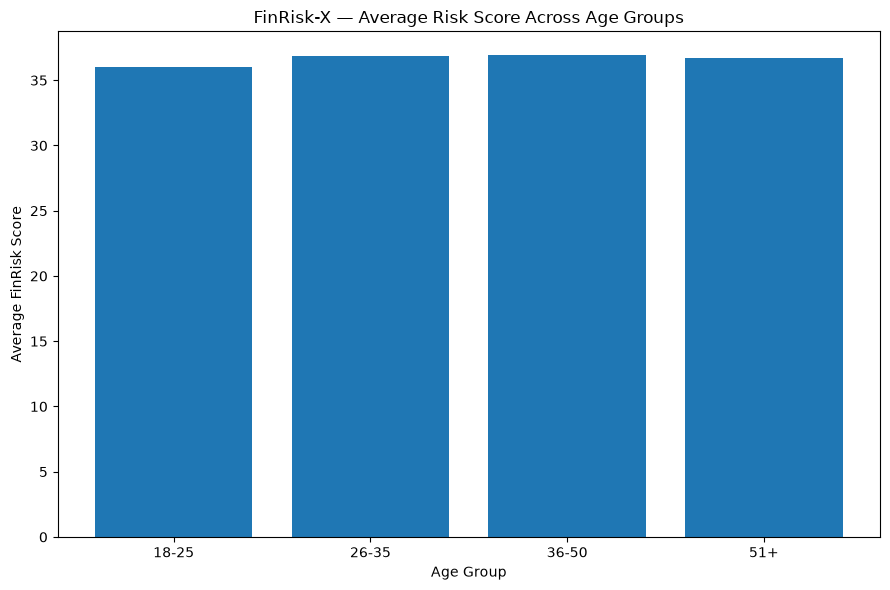

In [18]:
plt.figure(figsize=(9, 6))

plt.bar(
    age_fairness["age_group"].astype(str),
    age_fairness["average_finrisk_score"]
)

plt.xlabel("Age Group")
plt.ylabel("Average FinRisk Score")
plt.title(
    "FinRisk-X — Average Risk Score Across Age Groups"
)

plt.tight_layout()

plt.savefig(
    figures_path / "fairness_age_average_risk.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

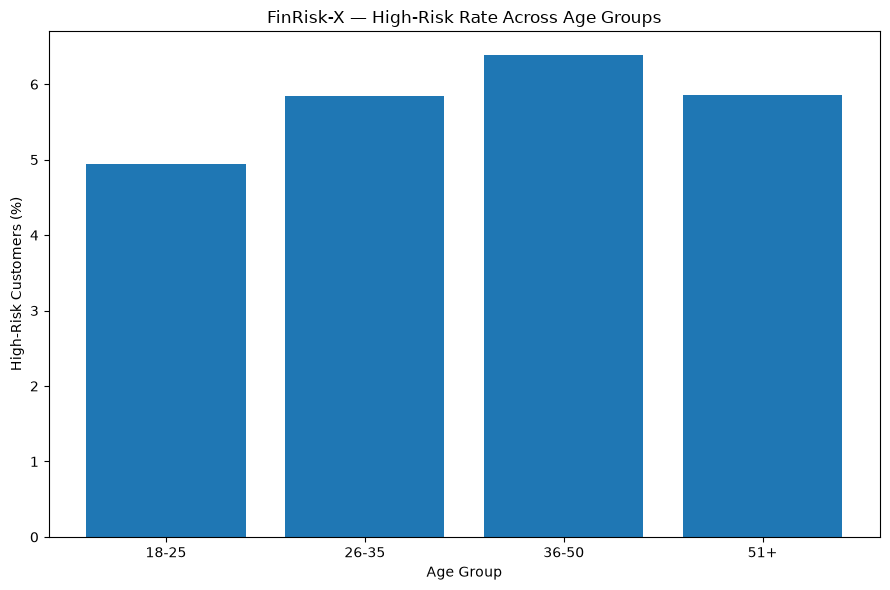

In [19]:
plt.figure(figsize=(9, 6))

plt.bar(
    age_fairness["age_group"].astype(str),
    age_fairness["high_risk_rate"]
)

plt.xlabel("Age Group")
plt.ylabel("High-Risk Customers (%)")
plt.title(
    "FinRisk-X — High-Risk Rate Across Age Groups"
)

plt.tight_layout()

plt.savefig(
    figures_path / "fairness_age_high_risk_rate.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

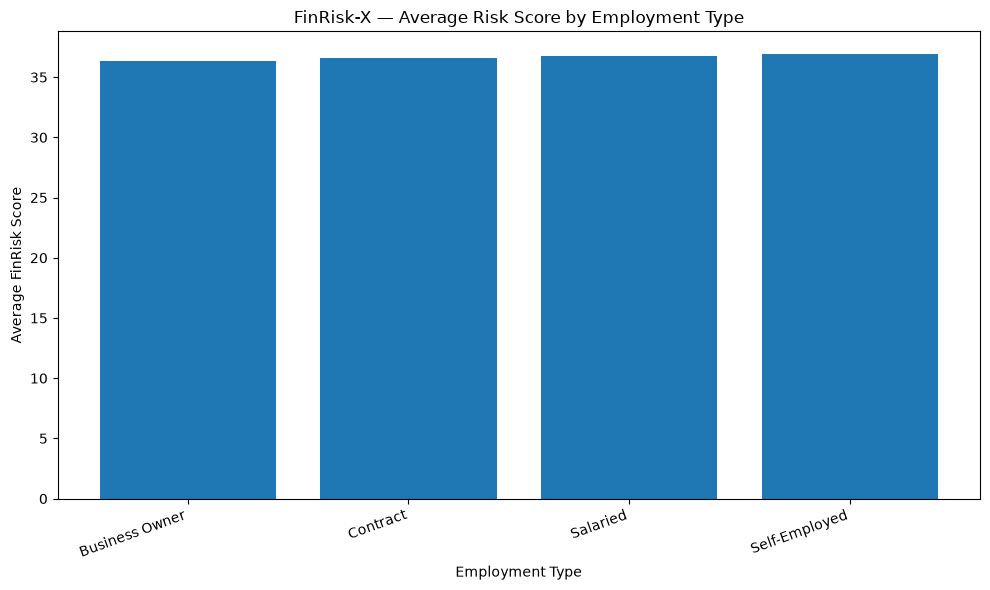

In [20]:
plt.figure(figsize=(10, 6))

plt.bar(
    employment_fairness["employment_type"].astype(str),
    employment_fairness["average_finrisk_score"]
)

plt.xlabel("Employment Type")
plt.ylabel("Average FinRisk Score")
plt.title(
    "FinRisk-X — Average Risk Score by Employment Type"
)

plt.xticks(rotation=20, ha="right")

plt.tight_layout()

plt.savefig(
    figures_path / "fairness_employment_average_risk.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

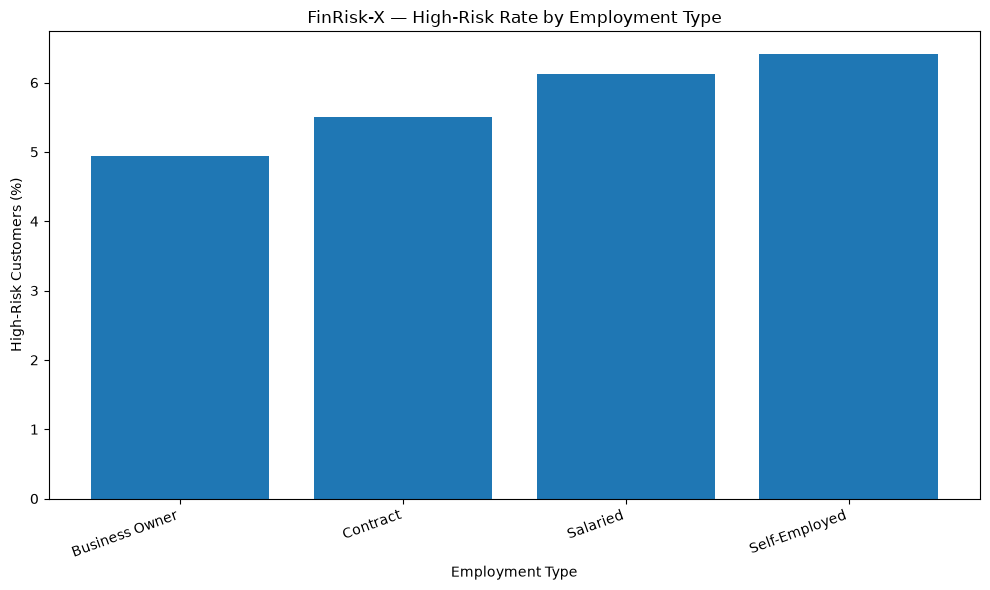

In [21]:
plt.figure(figsize=(10, 6))

plt.bar(
    employment_fairness["employment_type"].astype(str),
    employment_fairness["high_risk_rate"]
)

plt.xlabel("Employment Type")
plt.ylabel("High-Risk Customers (%)")
plt.title(
    "FinRisk-X — High-Risk Rate by Employment Type"
)

plt.xticks(rotation=20, ha="right")

plt.tight_layout()

plt.savefig(
    figures_path / "fairness_employment_high_risk_rate.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [22]:
def calculate_disparity(df, group_column):

    result = (
        df
        .groupby(group_column, observed=False)
        .agg(
            customer_count=("customer_id", "count"),
            high_risk_rate=(
                "finrisk_score",
                lambda x: (x >= 50).mean() * 100
            ),
            average_risk_score=(
                "finrisk_score",
                "mean"
            )
        )
        .reset_index()
    )

    reference_rate = result["high_risk_rate"].min()

    if reference_rate > 0:
        result["risk_rate_ratio"] = (
            result["high_risk_rate"] /
            reference_rate
        )
    else:
        result["risk_rate_ratio"] = np.nan

    result["risk_rate_difference"] = (
        result["high_risk_rate"] -
        reference_rate
    )

    return result


age_disparity = calculate_disparity(
    fairness_data,
    "age_group"
)

employment_disparity = calculate_disparity(
    fairness_data,
    "employment_type"
)

print("Age-group disparity:")
display(age_disparity)

print("Employment-type disparity:")
display(employment_disparity)

Age-group disparity:


,age_group,customer_count,high_risk_rate,average_risk_score,risk_rate_ratio,risk_rate_difference
0,18-25,1112,4.946043,36.012546,1.000000,0.000000
1,26-35,2257,5.848471,36.872721,1.182455,0.902428
2,36-50,3510,6.381766,36.903409,1.290277,1.435723
3,51+,3121,5.863505,36.678496,1.185494,0.917462


Employment-type disparity:


,employment_type,customer_count,high_risk_rate,average_risk_score,risk_rate_ratio,risk_rate_difference
0,Business Owner,1540,4.935065,36.374865,1.000000,0.000000
1,Contract,962,5.509356,36.561804,1.116369,0.574291
2,Salaried,5488,6.122449,36.770111,1.240602,1.187384
3,Self-Employed,2010,6.417910,36.959262,1.300471,1.482846


In [23]:
age_disparity["fairness_review"] = np.where(
    age_disparity["risk_rate_ratio"] > 1.25,
    "Review Required",
    "No Significant Disparity"
)

employment_disparity["fairness_review"] = np.where(
    employment_disparity["risk_rate_ratio"] > 1.25,
    "Review Required",
    "No Significant Disparity"
)

print("Age fairness:")
display(age_disparity)

print("Employment fairness:")
display(employment_disparity)

Age fairness:


,age_group,customer_count,high_risk_rate,average_risk_score,risk_rate_ratio,risk_rate_difference,fairness_review
0,18-25,1112,4.946043,36.012546,1.000000,0.000000,No Significant Disparity
1,26-35,2257,5.848471,36.872721,1.182455,0.902428,No Significant Disparity
2,36-50,3510,6.381766,36.903409,1.290277,1.435723,Review Required
3,51+,3121,5.863505,36.678496,1.185494,0.917462,No Significant Disparity


Employment fairness:


,employment_type,customer_count,high_risk_rate,average_risk_score,risk_rate_ratio,risk_rate_difference,fairness_review
0,Business Owner,1540,4.935065,36.374865,1.000000,0.000000,No Significant Disparity
1,Contract,962,5.509356,36.561804,1.116369,0.574291,No Significant Disparity
2,Salaried,5488,6.122449,36.770111,1.240602,1.187384,No Significant Disparity
3,Self-Employed,2010,6.417910,36.959262,1.300471,1.482846,Review Required


In [24]:
age_fairness.to_csv(
    processed_path / "fairness_age_analysis.csv",
    index=False
)

employment_fairness.to_csv(
    processed_path / "fairness_employment_analysis.csv",
    index=False
)

age_disparity.to_csv(
    processed_path / "fairness_age_disparity.csv",
    index=False
)

employment_disparity.to_csv(
    processed_path / "fairness_employment_disparity.csv",
    index=False
)

print("Fairness analysis files saved successfully.")

Fairness analysis files saved successfully.


In [25]:
expected_files = [
    processed_path / "fairness_age_analysis.csv",
    processed_path / "fairness_employment_analysis.csv",
    processed_path / "fairness_age_disparity.csv",
    processed_path / "fairness_employment_disparity.csv",

    figures_path / "fairness_age_average_risk.svg",
    figures_path / "fairness_age_high_risk_rate.svg",
    figures_path / "fairness_employment_average_risk.svg",
    figures_path / "fairness_employment_high_risk_rate.svg"
]

print("\nPhase 13 Output Validation\n")
print("-" * 50)

for file in expected_files:
    print(
        f"{file.name:<45}",
        "✓" if file.exists() else "✗"
    )


Phase 13 Output Validation

--------------------------------------------------
fairness_age_analysis.csv                     ✓
fairness_employment_analysis.csv              ✓
fairness_age_disparity.csv                    ✓
fairness_employment_disparity.csv             ✓
fairness_age_average_risk.svg                 ✓
fairness_age_high_risk_rate.svg               ✓
fairness_employment_average_risk.svg          ✓
fairness_employment_high_risk_rate.svg        ✓
